# Traffic-AI — Model Comparison
Compare **Linear Regression, Random Forest, and XGBoost** on the same traffic dataset using a chronological train/test split.


Metrics:
- **MAE** — lower is better
- **RMSE** — lower is better
- **R²** — higher is better

For time-series traffic data, we use a chronological split rather than randomly shuffling rows to reduce leakage from future observations.

> **Note:** this notebook splits by row order on the raw CSV (which is stored junction by junction), so its test set is only the end of the last junctions and it uses no lag features. Its numbers are NOT comparable with the production pipeline. The official comparison is `backend/model_comparison.py` (API: `/api/v1/model-comparison`, dashboard Analytics page), which uses the same features and chronological split as the saved XGBoost model.

In [1]:
# Cell 1: Imports and configuration
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# ---- EDIT THESE SETTINGS TO MATCH YOUR PROJECT ----
# Run this notebook from the project root, or change DATA_PATH accordingly.
DATA_PATH = "../data/raw/traffic.csv"

# Set this to the column you want to predict (e.g. traffic_volume, vehicles, vehicle_count).
TARGET_COLUMN = "Vehicles"

# Optional: specify feature columns. Use None to automatically use all columns
# except the target. Remove ID columns, leakage columns, and non-predictive text.
FEATURE_COLUMNS = None

# Fraction of earliest records used for training; latest records are held out for testing.
TRAIN_FRACTION = 0.80
RANDOM_STATE = 42

print("Configuration ready. Dataset path:", DATA_PATH)

Configuration ready. Dataset path: ../data/raw/traffic.csv


In [2]:
# Cell 2: Load dataset
data_path = Path(DATA_PATH)

if not data_path.exists():
    # Help locate CSV files if the default path is not correct.
    candidates = list(Path(".").glob("**/*.csv"))
    candidates = [p for p in candidates if "node_modules" not in str(p) and ".venv" not in str(p) and "venv" not in str(p)]
    print(f"Could not find: {data_path}")
    print("\nCSV files found in this project:")
    for p in candidates[:50]:
        print(" -", p)
    raise FileNotFoundError(
        "Update DATA_PATH in Cell 1 to the correct CSV path, then rerun this cell."
    )

df = pd.read_csv(data_path)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (48120, 4)


,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041



Columns:
['DateTime', 'Junction', 'Vehicles', 'ID']


## Check the target and features
If the target column is not found, use the printed column names to update `TARGET_COLUMN` in Cell 1. For a fair comparison, all models must use the same target and train/test rows.

In [3]:
# Cell 3: Prepare data
if TARGET_COLUMN not in df.columns:
    raise KeyError(
        f"Target '{TARGET_COLUMN}' not found. Available columns: {df.columns.tolist()}\n"
        "Change TARGET_COLUMN in Cell 1."
    )

# Remove rows where the target is missing or cannot be interpreted as numeric.
working = df.copy()
working[TARGET_COLUMN] = pd.to_numeric(working[TARGET_COLUMN], errors="coerce")
working = working.dropna(subset=[TARGET_COLUMN]).reset_index(drop=True)

if FEATURE_COLUMNS is None:
    feature_cols = [c for c in working.columns if c != TARGET_COLUMN]
else:
    missing = [c for c in FEATURE_COLUMNS if c not in working.columns]
    if missing:
        raise KeyError(f"These feature columns were not found: {missing}")
    feature_cols = list(FEATURE_COLUMNS)

if not feature_cols:
    raise ValueError("No feature columns remain. Set FEATURE_COLUMNS in Cell 1.")

X = working[feature_cols].copy()
y = working[TARGET_COLUMN].copy()

# Drop columns that are entirely empty and likely identifier-only columns can be
# removed manually via FEATURE_COLUMNS if necessary.
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    X = X.drop(columns=all_missing)
    feature_cols = X.columns.tolist()
    print("Dropped all-missing feature columns:", all_missing)

# Convert date/time-like strings into numeric components where possible.
for col in X.columns:
    if pd.api.types.is_datetime64_any_dtype(X[col]):
        X[col + "_year"] = X[col].dt.year
        X[col + "_month"] = X[col].dt.month
        X[col + "_day"] = X[col].dt.day
        X[col + "_hour"] = X[col].dt.hour
        X = X.drop(columns=[col])
    elif X[col].dtype == "object":
        parsed = pd.to_datetime(X[col], errors="coerce")
        # Only convert if most non-null values parse as dates and the column is not a label.
        non_null = X[col].notna().sum()
        if non_null > 0 and parsed.notna().sum() / non_null >= 0.8:
            X[col + "_year"] = parsed.dt.year
            X[col + "_month"] = parsed.dt.month
            X[col + "_day"] = parsed.dt.day
            X[col + "_hour"] = parsed.dt.hour
            X = X.drop(columns=[col])

# Drop columns that look like unique row IDs (high-cardinality identifier risk).
id_like = []
for col in X.columns:
    name = col.lower()
    unique_ratio = X[col].nunique(dropna=True) / max(len(X), 1)
    if name in {"id", "record_id", "row_id", "index"} or (name.endswith("_id") and unique_ratio > 0.5):
        id_like.append(col)
if id_like:
    X = X.drop(columns=id_like)
    print("Dropped ID-like columns:", id_like)

if X.shape[1] == 0:
    raise ValueError("No usable features left. Set FEATURE_COLUMNS to meaningful input columns.")

split_at = int(len(X) * TRAIN_FRACTION)
if split_at < 2 or len(X) - split_at < 1:
    raise ValueError("Dataset is too small for the selected train/test split.")

X_train, X_test = X.iloc[:split_at].copy(), X.iloc[split_at:].copy()
y_train, y_test = y.iloc[:split_at].copy(), y.iloc[split_at:].copy()

print(f"Rows after cleaning: {len(working)}")
print(f"Features used ({X.shape[1]}): {X.columns.tolist()}")
print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Target: {TARGET_COLUMN}")

Dropped ID-like columns: ['ID']
Rows after cleaning: 48120
Features used (2): ['DateTime', 'Junction']
Train rows: 38496 | Test rows: 9624
Target: Vehicles


In [4]:
# Cell 4: Preprocessing pipeline
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Junction']
Categorical features: ['DateTime']


In [5]:
# Cell 5: Build models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        min_samples_leaf=2
    )
}

# XGBoost is optional. If it's installed, include it in the comparison.
try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    print("XGBoost found: all three models will be compared.")
except ImportError:
    print("XGBoost is not installed. Comparing Linear Regression and Random Forest.")
    print("To include XGBoost, install it with: pip install xgboost")

print("Models:", list(models.keys()))

XGBoost found: all three models will be compared.
Models: ['Linear Regression', 'Random Forest', 'XGBoost']


In [6]:
# Cell 6: Train and evaluate models
results = []
predictions = {}

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred) if len(y_test) >= 2 else np.nan

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    predictions[model_name] = y_pred
    print(f"{model_name}: MAE={mae:.4f}, RMSE={rmse:.4f}, R²={r2:.4f}")

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_df.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.3f}"}))

Linear Regression: MAE=10.5698, RMSE=13.6093, R²=-0.8643


Random Forest: MAE=6.4957, RMSE=9.9990, R²=-0.0064


XGBoost: MAE=6.5200, RMSE=9.8573, R²=0.0219


,Model,MAE,RMSE,R2
0,Random Forest,6.496,9.999,-0.006
1,XGBoost,6.520,9.857,0.022
2,Linear Regression,10.570,13.609,-0.864


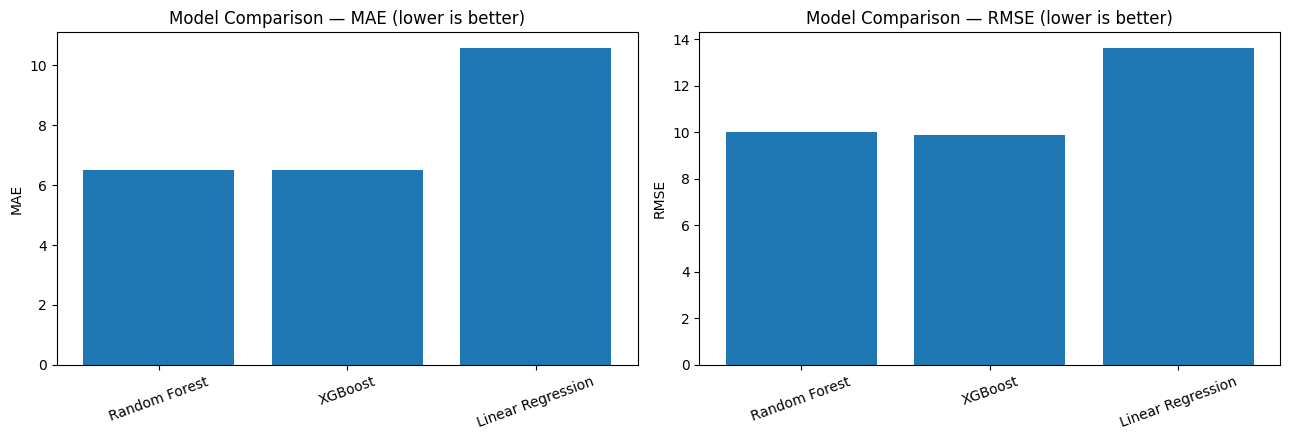

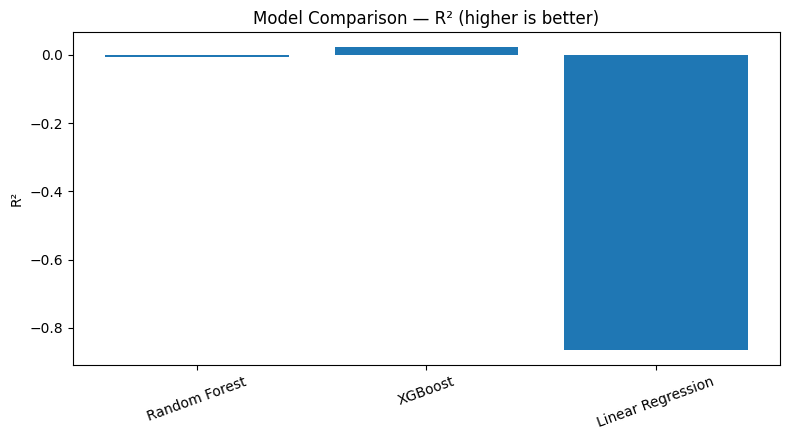

In [7]:
# Cell 7: Visualize metric comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(results_df["Model"], results_df["MAE"])
axes[0].set_title("Model Comparison — MAE (lower is better)")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(results_df["Model"], results_df["RMSE"])
axes[1].set_title("Model Comparison — RMSE (lower is better)")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.bar(results_df["Model"], results_df["R2"])
plt.title("Model Comparison — R² (higher is better)")
plt.ylabel("R²")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

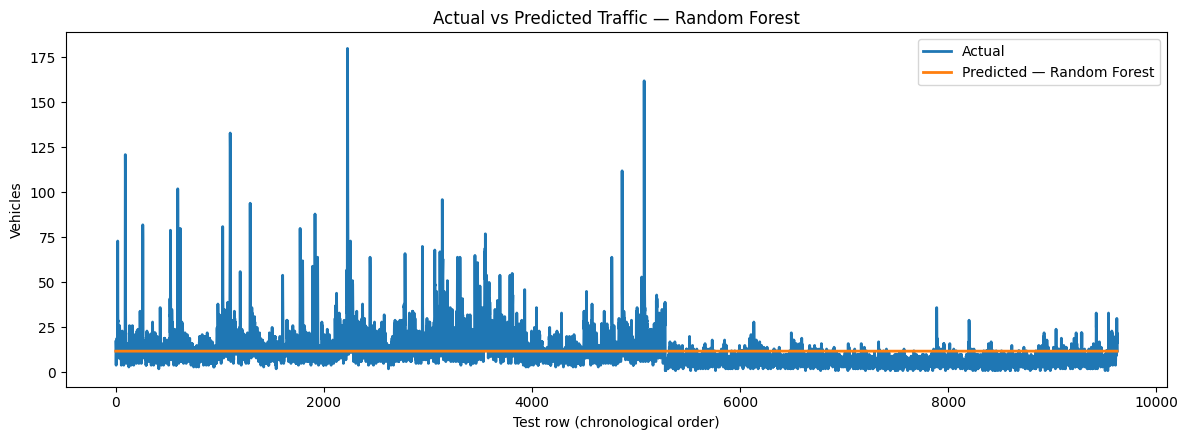

Best model by MAE: Random Forest
Reminder: lower MAE/RMSE is better; higher R² is better.


In [8]:
# Cell 8: Plot actual vs predicted values for the best model by MAE
best_model = results_df.iloc[0]["Model"]
best_pred = predictions[best_model]

plt.figure(figsize=(12, 4.5))
plt.plot(np.asarray(y_test), label="Actual", linewidth=2)
plt.plot(best_pred, label=f"Predicted — {best_model}", linewidth=2)
plt.title(f"Actual vs Predicted Traffic — {best_model}")
plt.xlabel("Test row (chronological order)")
plt.ylabel(TARGET_COLUMN)
plt.legend()
plt.tight_layout()
plt.show()

print("Best model by MAE:", best_model)
print("Reminder: lower MAE/RMSE is better; higher R² is better.")